# **실패 사례 분석 — 최종 모델 (오프라인) test**

> 최종 모델(DA3 + DINOv3, test ② 1.75 cm)의 **상자별 오차가 언제 커지나**를 본다. 예측은 메인 노트북 [F-2]가 저장한 `{split}_proposed_preds.csv` (test 채점에 쓴 바로 그 값) — **모델 · 예측을 바꾸지 않는 사후 분석**이다. 같은 경향이 val에도 있는지 함께 확인해 test만의 우연과 구분한다.

| 셀 | 내용 |
| --- | --- |
| [A-0] | 상자별 분석표: 오차 + 요인 (가려짐 · 쓴 프레임 · 화면 끝 · 상자 크기 · 납작함 · focal · 장면 상자 수 · 화면 위치 · 레일 기울기) + 원인 분해 (STEP 1 · STEP 2 · 축 순서) |
| [A-1] | 오차 분포 · 실패 상자 정의 (상자별 ② cm 상위 10%) |
| [A-2] | 요인별 구간표 (영상 단위 bootstrap 95% CI, val 열 = 같은 경향 확인) |
| [A-3] | 다변수 회귀 (표준화 계수 · 영상 단위 cluster 표준오차) + Spearman — 요인을 함께 넣어도 남는 관련 |
| [A-4] | 원인 분해: 실패 상자는 w · 형태비 중 무엇이 틀렸나, 축 순서 혼동 |
| [A-5] | 정성: test 오차 상위 12개 — 전체 화면 · 대표 crop · 가상 3D 상자 (보고서 그림) |
| [A-6] | 시스템 오류 (③): 미검출 · 정답 없는 트랙의 몫, 미검출 상자의 특징 |

**실행:** 런타임 > 모두 실행 (GPU 필요 없음, CPU로 충분). 결과 · 그림은 `outputs/step2/failure/`.


# **0. 설정 · 데이터** — 메인 노트북과 같은 코드

In [1]:
# [S-1] Drive 마운트 + 경로 + 한글 폰트 (폰트 설치가 실패해도 계속 진행)
from google.colab import drive
drive.mount('/content/drive')
import os, sys, glob, json, pickle, time, math, random, shutil, subprocess, urllib.request, socket

ROOT        = '/content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인'
PROJECT_DIR = f'{ROOT}/BoxSizing'
DATA_DIR    = f'{ROOT}/Dataset/Final Dataset'
CKPT_DIR    = f'{PROJECT_DIR}/checkpoints'
CACHE_DIR   = f'{PROJECT_DIR}/cache'                     # 트래킹 + 레일 캐시 (이미 있음)
OUT_DIR     = f'{PROJECT_DIR}/outputs/step1'             # fold 분할 · OOF 저장소
OUT2_DIR    = f'{PROJECT_DIR}/outputs/step2'             # 제안 방법 예측 CSV (OVMono3D 노트북이 읽음)
LOCAL_DATA  = '/content/data'
MAPPING_XLSX = {sp: f'{PROJECT_DIR}/{sp}_label_mapping.xlsx' for sp in ('train', 'val', 'test')}
for d in (OUT_DIR, OUT2_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

RUN_TEST = True                                          # train · val 재현 확인 → test 채점 (한 번) → 런타임 · 시각화 (test 영상)
SPLITS = ['train', 'val'] + (['test'] if RUN_TEST else [])


def video_path(sp, vid):
    p = f'{LOCAL_DATA}/{sp}/{vid}.mp4'
    return p if os.path.exists(p) else f'{DATA_DIR}/{sp}/{vid}.mp4'


# ---- 한글 폰트: Drive 캐시 → GitHub(10초) → apt(60초), 모두 실패해도 셀은 멈추지 않음 ----
import matplotlib.font_manager as fm, matplotlib.pyplot as plt
FONT = f'{PROJECT_DIR}/fonts/NanumGothic.ttf'
if not os.path.exists(FONT):
    os.makedirs(os.path.dirname(FONT), exist_ok=True)
    try:
        socket.setdefaulttimeout(10)
        urllib.request.urlretrieve('https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', FONT)
    except Exception as e:
        print('GitHub 폰트 다운로드 실패 → apt 시도:', type(e).__name__)
        subprocess.run('timeout 60 apt-get -qq -o Acquire::http::Timeout=10 install -y fonts-nanum > /dev/null 2>&1', shell=True)
        if os.path.exists('/usr/share/fonts/truetype/nanum/NanumGothic.ttf'):
            shutil.copy('/usr/share/fonts/truetype/nanum/NanumGothic.ttf', FONT)
    finally:
        socket.setdefaulttimeout(None)
if os.path.exists(FONT) and os.path.getsize(FONT) > 100_000:
    fm.fontManager.addfont(FONT); plt.rcParams['font.family'] = fm.FontProperties(fname=FONT).get_name()
else:
    print('⚠️ 한글 폰트 없음 → 그래프의 한글이 네모로 보일 수 있음 (결과에는 영향 없음)')
plt.rcParams['axes.unicode_minus'] = False
print('SPLITS =', SPLITS)

Mounted at /content/drive
SPLITS = ['train', 'val', 'test']


In [2]:
# [L-1] 장면 상수 · 레일 기하 · 라벨 / 매핑 / 캐시 로더 · (트랙, 정답) 표 · 기하 특징
import numpy as np, pandas as pd, cv2

RAIL_WIDTH_CM, SENSOR_W_MM, FRAME_W, FRAME_H = 62.3, 5.79, 1280, 720
BEST_ALPHA = 1.0                                         # bbox 아랫변(y2)에서 픽셀당 cm를 읽음 (STEP 1 결론)
MAP_COL = 'new_tracked_unique_id_VERSION5'               # 매핑 엑셀의 트랙 번호 열


def rail_scale_at_y_vec(near_y, far_y, near_w, far_w, y):
    t = np.clip((near_y - y) / np.maximum(near_y - far_y, 1e-6), 0.0, 1.15)
    return RAIL_WIDTH_CM / np.maximum(near_w + (far_w - near_w) * t, 1.0)


def vanish_y_of(q):
    ny, fy = q['near_y'], q['fy']; denom = fy - ny
    aL, aR = (q['fl'] - q['nl']) / denom, (q['fr'] - q['nr']) / denom
    y_lines = ny + (q['nr'] - q['nl']) / (aL - aR) if abs(aL - aR) > 1e-9 else None
    y_width = ny - q['near_w'] * (ny - fy) / (q['near_w'] - q['far_w'] + 1e-9)
    return float(y_width) if y_lines is None else float((y_lines + y_width) / 2)


def vanish_xy(q):
    y_v = vanish_y_of(q)
    t = (q['near_y'] - y_v) / max(q['near_y'] - q['fy'], 1e-6)
    mid_n, mid_f = (q['nl'] + q['nr']) / 2, (q['fl'] + q['fr']) / 2
    return mid_n + (mid_f - mid_n) * t, y_v


def load_labels(path):
    with open(path) as f:
        videos = json.load(f)['videos']
    out = {}
    for v in videos:
        objs = sorted(v['objects'], key=lambda o: o['box_id'])
        out[v['video_id']] = {'boxes': [{'w': float(o['size_cm']['w']), 'd': float(o['size_cm']['d']),
                                         'h': float(o['size_cm']['h']), 'box_id': int(o['box_id'])} for o in objs],
                              'focal_mm': float(v['camera']['focal_length_mm'])}
    print(f'📄 {os.path.basename(path)}: 영상 {len(out)}개, 상자 {sum(len(v["boxes"]) for v in out.values())}개')
    return out


def load_mapping(path, col=MAP_COL):
    m = pd.read_excel(path); out = {}
    for vid, g in m.groupby('video_id'):
        rows = []
        for _, r in g.sort_values('box_id_json').iterrows():
            try:
                trk = int(float(r[col]))
            except (TypeError, ValueError):
                trk = None
            rows.append({'box_id': int(r['box_id_json']), 'trk': trk,
                         'removed': str(r.get('note', '')).strip().upper() == 'REMOVED'})
        out[str(vid)] = rows
    n_ok = sum(r['trk'] is not None and not r['removed'] for v in out.values() for r in v)
    print(f'🗂 {os.path.basename(path)}: 영상 {len(out)}개 → 트랙과 연결된 GT {n_ok}개')
    return out


def load_cache(d):
    recs = {}
    for p in sorted(glob.glob(f'{d}/*.pkl')):
        with open(p, 'rb') as f:
            r = pickle.load(f)
        recs[r['video_id']] = r
    return recs


def _rep(t, min_side_px=3):
    """대표 프레임 = bbox 면적 최대 (너무 작으면 None)"""
    bb = t['bbox']; k = int(((bb[:, 2] - bb[:, 0]) * (bb[:, 3] - bb[:, 1])).argmax())
    x1, y1, x2, y2 = bb[k]
    return None if (x2 <= x1 + min_side_px or y2 <= y1 + min_side_px) else k


def _row(split, vid, rec, lab, t, k, g, n_g):
    q = rec['quad']; x1, y1, x2, y2 = t['bbox'][k]
    return {'split': split, 'vid': vid, 'tid': int(t['tid']), 'box_id': -1 if g is None else g['box_id'],
            'mapped': g is not None, 'rep_fi': int(t['fi'][k]), 'step': rec['step'],
            'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2, 'bw': x2 - x1, 'bh': y2 - y1,
            'w_gt': np.nan if g is None else g['w'], 'd_gt': np.nan if g is None else g['d'],
            'h_gt': np.nan if g is None else g['h'], 'n_gt': n_g, 'focal_mm': lab['focal_mm'],
            'near_y': q['near_y'], 'far_y': q['far_y'], 'near_w': q['near_w'], 'far_w': q['far_w']}


def build_tables(recs, labels, split, mapping):
    """반환: (매핑 쌍 표, 모든 트랙 표). REMOVED 상자의 트랙은 모든 트랙 표에서도 제외."""
    pairs, alltrk = [], []
    for vid, rec in recs.items():
        if vid not in labels or rec['quad'] is None:
            continue
        lab, rows = labels[vid], mapping.get(vid, [])
        gt_by = {g['box_id']: g for g in lab['boxes']}
        removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
        link = {m['trk']: gt_by[m['box_id']] for m in rows if not m['removed'] and m['trk'] is not None}
        for t in rec['tracks']:
            tid = int(t['tid'])
            if tid in removed_trk:
                continue
            k = _rep(t)
            if k is None:
                continue
            r = _row(split, vid, rec, lab, t, k, link.get(tid), len(lab['boxes']))
            alltrk.append(r)
        for m in rows:                                       # 매핑 쌍 표 (예전과 같은 순서: 매핑 엑셀 순)
            if m['removed'] or m['trk'] is None:
                continue
            t = next((t for t in rec['tracks'] if int(t['tid']) == m['trk']), None)
            k = _rep(t) if t is not None else None
            if k is not None:
                pairs.append(_row(split, vid, rec, lab, t, k, gt_by[m['box_id']], len(lab['boxes'])))
    return pd.DataFrame(pairs), pd.DataFrame(alltrk)


def scale_at(df, y):
    return rail_scale_at_y_vec(df.near_y.values, df.far_y.values, df.near_w.values, df.far_w.values, np.asarray(y, float))


def add_features(df, recs):
    """기하 특징 (추론 때 알 수 있는 값만): 레일 방향 sin · cos, log focal, log bbox 비율, log 픽셀당 cm"""
    d = df.copy().reset_index(drop=True)
    y_ref = d.y1 + BEST_ALPHA * (d.y2 - d.y1)
    d['w_base'] = d.bw * scale_at(d, y_ref)
    d['B_gt'] = d.w_gt / d.w_base
    sin_t, cos_t = [], []
    for _, r in d.iterrows():
        rec = recs[r.split][r.vid]; xv, yv = vanish_xy(rec['quad'])
        dx, dy = xv - (r.x1 + r.x2) / 2, r.y2 - yv
        if not (np.isfinite(dx) and np.isfinite(dy)) or dy <= 1:
            dx, dy = rec['vx'], -rec['vy']
            if dy < 0: dx, dy = -dx, -dy
        n = np.hypot(dx, dy) + 1e-9; sin_t.append(dx / n); cos_t.append(dy / n)
    d['sin_t'], d['cos_t'] = sin_t, cos_t
    d['logB'] = np.log(d.B_gt)
    d['log_s'] = np.log(scale_at(d, y_ref))
    d['log_f'] = np.log(d.focal_mm)
    d['log_aspect'] = np.log(d.bw / d.bh)
    d['log_dw'], d['log_hw'] = np.log(d.d_gt / d.w_gt), np.log(d.h_gt / d.w_gt)
    return d


def sort3(a):
    return -np.sort(-np.asarray(a, float), axis=-1)

In [3]:
# [M-1] 공용 도구 — 학습 설정 · 지표 (① ② ③) · 출력 도우미
import torch, torch.nn as nn

DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
BS, NO_STD = 32, {'sin_t', 'cos_t'}
CKPT2 = f'{CKPT_DIR}/step2'; os.makedirs(CKPT2, exist_ok=True)       # 최종 head 가중치 위치 (ablation 노트북과 같음)
GEO = ['log_f', 'sin_t', 'cos_t', 'log_aspect', 'log_s']             # STEP 1 보조 입력: log focal · 레일 방향 · log bbox 가로세로 비 · log 픽셀당 cm
FS, T2 = ['log_f', 'log_s'], ['log_dw', 'log_hw']                    # STEP 2 보조 입력 · 출력


def hr(title):
    print('\n' + '━' * 90); print(title)


def dim_err(P, G):
    # 지표 ② (상자 하나씩): 세 변 큰 순 정렬 후 같은 순위끼리 → (cm 평균, % 평균)
    Gs = sort3(G); d = np.abs(sort3(P) - Gs)
    return d.mean(1).mean(), (d / Gs).mean(1).mean() * 100


def full_errors(labels, mapping, pred, cols=('w', 'd', 'h')):
    # 반환: 매칭 쌍 · 미검출 정답 · 정답 없는 트랙 — 상자마다 (cm 오차, % 오차)
    cols = list(cols)
    pidx = pred.set_index(['vid', 'tid'])
    matched, miss, fp = [], [], []
    for vid in sorted(labels):
        rows = mapping.get(vid, [])
        removed_box = {m['box_id'] for m in rows if m['removed']}
        removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
        link = {m['box_id']: m['trk'] for m in rows if not m['removed'] and m['trk'] is not None}
        vid_trks = set(pred.loc[pred.vid == vid, 'tid'].astype(int)) - removed_trk
        for g in labels[vid]['boxes']:
            if g['box_id'] in removed_box:
                continue
            gs = sort3([g['w'], g['d'], g['h']]); t = link.get(g['box_id'])
            if t is not None and (vid, t) in pidx.index:
                diff = np.abs(sort3(pidx.loc[(vid, t), cols].values.astype(float)) - gs)
                matched.append((float(diff.mean()), float((diff / gs).mean() * 100)))
            else:
                miss.append((float(gs.mean()), 100.0))                          # 예측을 (0, 0, 0)으로 → 세 변 모두 100%
        for t in vid_trks - set(link.values()):
            p = sort3(pidx.loc[(vid, t), cols].values.astype(float))
            fp.append((float(p.mean()), 100.0))                                  # 정답을 (0, 0, 0)으로 → 100%로 정의
    return matched, miss, fp


def box_records(labels, mapping, pred, cols=('w', 'd', 'h')):
    """full_errors와 같은 정의, 상자마다 (영상, 종류, cm, %, 정답 가장 긴 변 · 짧은 변) — 구간별 · bootstrap용"""
    cols = list(cols); pidx = pred.set_index(['vid', 'tid']); out = []
    for vid in sorted(labels):
        rows = mapping.get(vid, [])
        removed_box = {m['box_id'] for m in rows if m['removed']}
        removed_trk = {m['trk'] for m in rows if m['removed'] and m['trk'] is not None}
        link = {m['box_id']: m['trk'] for m in rows if not m['removed'] and m['trk'] is not None}
        n_box = len(labels[vid]['boxes'])
        for g in labels[vid]['boxes']:
            if g['box_id'] in removed_box: continue
            gs = sort3([g['w'], g['d'], g['h']]); t = link.get(g['box_id'])
            if t is not None and (vid, t) in pidx.index:
                diff = np.abs(sort3(pidx.loc[(vid, t), cols].values.astype(float)) - gs)
                out.append((vid, n_box, '매칭', float(diff.mean()), float((diff / gs).mean() * 100), gs[0], gs[2]))
            else:
                out.append((vid, n_box, '미검출', float(gs.mean()), 100.0, gs[0], gs[2]))
        vid_trks = set(pred.loc[pred.vid == vid, 'tid'].astype(int)) - removed_trk
        for t in vid_trks - set(link.values()):
            p = sort3(pidx.loc[(vid, t), cols].values.astype(float))
            out.append((vid, n_box, '정답 없음', float(p.mean()), 100.0, np.nan, np.nan))
    return pd.DataFrame(out, columns=['vid', 'n_box', 'kind', 'cm', 'pct', 'long', 'short'])


def boot_ci(df, col, n=2000, seed=0):
    """영상 단위 bootstrap 95% CI (영상을 복원추출, 상자 평균)"""
    if not len(df): return (np.nan, np.nan)
    rng = np.random.default_rng(seed); vids = df.vid.unique(); g = {v: df.loc[df.vid == v, col].values for v in vids}
    res = [np.concatenate([g[v] for v in rng.choice(vids, len(vids))]).mean() for _ in range(n)]
    return tuple(np.percentile(res, [2.5, 97.5]))


In [4]:
# [D-1] 라벨 · 캐시 · 매핑 → 매핑 쌍 표 + 모든 트랙 표, train 영상 단위 5-fold (예전 분할 파일 그대로)
LABELS = {sp: load_labels(f'{DATA_DIR}/{sp}_label.json') for sp in SPLITS}
RECS   = {sp: load_cache(f'{CACHE_DIR}/{sp}') for sp in SPLITS}
MAPS   = {sp: load_mapping(MAPPING_XLSX[sp]) for sp in SPLITS}
PAIRS, ALL = {}, {}
for sp in SPLITS:
    p, a = build_tables(RECS[sp], LABELS[sp], sp, MAPS[sp])
    PAIRS[sp], ALL[sp] = add_features(p, RECS), add_features(a, RECS)
    print(f'{sp}: 매핑 쌍 {len(PAIRS[sp])} | 모든 트랙 {len(ALL[sp])} (그중 정답 없는 트랙 {int((~ALL[sp].mapped).sum())})')
TRN = PAIRS['train']

N_FOLD, SEED = 5, 0
FOLD_CSV = f'{OUT_DIR}/step1_folds.csv'
_key = lambda d: (d.vid + '|' + d.tid.astype(str) + '|' + d.box_id.astype(str)).tolist()
if os.path.exists(FOLD_CSV):
    F = pd.read_csv(FOLD_CSV)
    assert _key(F) == _key(TRN), 'train 쌍이 예전 분할 파일과 다름 → 저장된 fold 가중치를 쓸 수 없음 (매핑 · 캐시 확인)'
    TRN['fold'] = F['fold'].values
else:                                                    # 파일이 없을 때만 새로 만듦 (이 경우 가중치도 새로 학습됨)
    from sklearn.model_selection import StratifiedGroupKFold
    TRN['fold'] = -1
    fbin = pd.cut(TRN.focal_mm, [0, 8, 15, 25, 100], labels=False)
    for k, (_, te) in enumerate(StratifiedGroupKFold(N_FOLD, shuffle=True, random_state=SEED).split(TRN, fbin, groups=TRN.vid)):
        TRN.loc[te, 'fold'] = k
    TRN[['vid', 'tid', 'box_id', 'fold']].to_csv(FOLD_CSV, index=False)
VID_FOLD = TRN.groupby('vid').fold.first().to_dict()
ALL['train']['fold'] = ALL['train'].vid.map(VID_FOLD).fillna(-1).astype(int)   # OOF: 그 영상이 빠진 fold의 모델로 예측
for sp in SPLITS:
    if sp != 'train':
        ALL[sp]['fold'] = -1                                                     # val · test: fold 모델 5개 평균
print('train fold별 영상 수:', TRN.groupby('fold').vid.nunique().to_dict())

📄 train_label.json: 영상 100개, 상자 918개
📄 val_label.json: 영상 49개, 상자 467개
📄 test_label.json: 영상 50개, 상자 476개
🗂 train_label_mapping.xlsx: 영상 100개 → 트랙과 연결된 GT 899개
🗂 val_label_mapping.xlsx: 영상 49개 → 트랙과 연결된 GT 461개
🗂 test_label_mapping.xlsx: 영상 50개 → 트랙과 연결된 GT 469개
train: 매핑 쌍 899 | 모든 트랙 910 (그중 정답 없는 트랙 11)
val: 매핑 쌍 461 | 모든 트랙 467 (그중 정답 없는 트랙 6)
test: 매핑 쌍 469 | 모든 트랙 477 (그중 정답 없는 트랙 8)
train fold별 영상 수: {0: 20, 1: 20, 2: 20, 3: 19, 4: 21}


In [5]:
# [P-0] crop 도구 — letterbox · 캐시 저장 (여유 10%, letterbox 224)
IMG, PAD = 224, 0.10


def letterbox(img, size=IMG):
    h, w = img.shape[:2]; s = size / max(h, w)
    r = cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    out = np.zeros((size, size, 3), np.uint8)
    oy, ox = (size - r.shape[0]) // 2, (size - r.shape[1]) // 2
    out[oy:oy + r.shape[0], ox:ox + r.shape[1]] = r
    return out


def safe_npz(path):
    # 저장이 중간에 끊겨 깨진 캐시는 지우고 None (다시 만듦)
    if not os.path.exists(path):
        return None
    try:
        z = np.load(path, allow_pickle=True); z.files; return z
    except Exception as e:
        print(f'⚠️ 깨진 캐시 삭제 후 다시 만듦: {os.path.basename(path)} ({type(e).__name__})'); os.remove(path); return None


def safe_save(path, **arrays):
    # 로컬에 먼저 저장한 뒤 Drive로 옮김 → 저장 중 끊겨도 Drive에 깨진 파일이 남지 않음
    tmp = f'/content/_tmp_{os.path.basename(path)}'
    np.savez_compressed(tmp, **arrays); shutil.move(tmp, path)


In [6]:
# [P-1] 프레임 선택 (메인 [P-1]의 함수만) — 트랙마다 치수 추정에 쓴 프레임 (가려짐 적은 순 최대 8장) 표
K_NEW, NEAR_NEW, MIN_GAP = 8, 0.5, 2                 # 가려짐 적은 순 최대 8장 · 면적이 최대의 50% 이상 · 프레임 간격 2 이상
MODE = 'multi_occ_k8'


def occlusion(bb_self, others):
    if not len(others):
        return 0.0
    o = np.asarray(others, float)
    iw = np.clip(np.minimum(bb_self[2], o[:, 2]) - np.maximum(bb_self[0], o[:, 0]), 0, None)
    ih = np.clip(np.minimum(bb_self[3], o[:, 3]) - np.maximum(bb_self[1], o[:, 1]), 0, None)
    area = max((bb_self[2] - bb_self[0]) * (bb_self[3] - bb_self[1]), 1e-6)
    return float(min(1.0, (iw * ih).sum() / area))


def select_frames(bb, occ, k=K_NEW, near=NEAR_NEW):
    area = (bb[:, 2] - bb[:, 0]) * (bb[:, 3] - bb[:, 1])
    valid = (bb[:, 2] > bb[:, 0] + 3) & (bb[:, 3] > bb[:, 1] + 3)
    order = [int(i) for i in np.argsort(-area) if valid[i]]
    if not order:
        return []
    cand = sorted([i for i in order if area[i] >= near * area[order[0]]], key=lambda i: (round(occ[i], 3), -area[i]))
    sel = []
    for i in cand:
        if all(abs(i - j) >= MIN_GAP for j in sel):
            sel.append(i)
        if len(sel) == k:
            break
    return sel


def frame_table(split, mapped=True):
    # mapped=True: 수작업 매핑된 트랙 (학습 · 지표 ① ②) / False: 정답 없는 트랙 (지표 ③, REMOVED 제외)
    rows = []
    for vid, rec in RECS[split].items():
        if vid not in LABELS[split] or rec['quad'] is None:
            continue
        lab, maps = LABELS[split][vid], MAPS[split].get(vid, [])
        gt_by = {g['box_id']: g for g in lab['boxes']}
        link = {m['trk']: gt_by[m['box_id']] for m in maps if not m['removed'] and m['trk'] is not None and m['box_id'] in gt_by}
        removed_trk = {m['trk'] for m in maps if m['removed'] and m['trk'] is not None}
        at = {}                                                        # 샘플 프레임 → [(트랙, bbox)]
        for t in rec['tracks']:
            for fi, b in zip(t['fi'], t['bbox']):
                at.setdefault(int(fi), []).append((int(t['tid']), b))
        for t in rec['tracks']:
            tid = int(t['tid']); g = link.get(tid)
            if mapped and g is None:
                continue
            if not mapped and (g is not None or tid in removed_trk or _rep(t) is None):
                continue
            occ = np.array([occlusion(b, [o for t2, o in at[int(fi)] if t2 != tid]) for fi, b in zip(t['fi'], t['bbox'])])
            for j in select_frames(t['bbox'], occ):
                r = _row(split, vid, rec, lab, t, j, g, len(lab['boxes']))
                r['occ'] = occ[j]
                rows.append(r)
    return add_features(pd.DataFrame(rows), RECS) if rows else None


# **1. 상자별 분석표 · 오차 분포**

In [7]:
# [A-0] 상자별 분석표 — 최종 모델의 상자별 예측(메인 [F-2]가 저장한 {split}_proposed_preds.csv, test 채점에 쓴 바로 그 값) + 요인
#  - 대상: 매칭 쌍(수작업 매핑으로 정답과 연결된 트랙). 지표 ② = 세 변 큰 순 정렬 후 같은 순위끼리 평균 절대오차
#  - 요인 (모두 추론 때 알 수 있거나 정답에서 오는 값):
#      가려짐 (치수 추정에 쓴 프레임의 평균 · 최소) · 쓴 프레임 수 · 화면 끝에 닿은 프레임 비율 · bbox 가로 px
#      상자 크기 (긴 변 · 짧은 변 · 납작함) · focal · 장면 상자 수 · 화면 위치 (레일 가까운 쪽 0 ~ 먼 쪽 1) · 레일 기울기 |sin|
#  - 원인 분해: STEP 1만 틀린 경우(형태비 = 정답)와 STEP 2만 틀린 경우(w = 정답)의 ② → 더 큰 쪽이 주 원인
#    축 순서 다름 = 예측에서 가장 긴 변이 정답과 다른 축(w · d · h)인 경우 (w · d 분할 혼동 등)
ANA_SPLITS = ['test', 'val']                                             # test 분석 + 같은 패턴이 val에도 있는지 확인
EDGE_PX = 3
ANA_DIR = f'{OUT2_DIR}/failure'; os.makedirs(ANA_DIR, exist_ok=True)


def box_table(sp):
    P = pd.read_csv(f'{OUT2_DIR}/{sp}_proposed_preds.csv')
    A = ALL[sp][ALL[sp].mapped].merge(P[['vid', 'tid', 'w', 'd', 'h']], on=['vid', 'tid'], how='left').reset_index(drop=True)
    assert A.w.notna().all(), f'{sp}: 예측 없는 매칭 트랙'
    G, Pp = A[['w_gt', 'd_gt', 'h_gt']].values, A[['w', 'd', 'h']].values; Gs = sort3(G); diff = np.abs(sort3(Pp) - Gs)
    A['② cm'], A['② %'] = diff.mean(1), (diff / Gs).mean(1) * 100
    A['긴 변'], A['중간 변'], A['짧은 변'] = Gs.T
    A['긴 변 오차'], A['중간 변 오차'], A['짧은 변 오차'] = diff.T
    A['w 오차 %'] = (A.w - A.w_gt) / A.w_gt * 100
    A['e_w'] = np.log(A.w / A.w_gt); A['e_dw'] = np.log(A.d / A.w) - np.log(A.d_gt / A.w_gt); A['e_hw'] = np.log(A.h / A.w) - np.log(A.h_gt / A.w_gt)
    w, wg = A.w.values, A.w_gt.values
    s1 = np.c_[w, w * A.d_gt / wg, w * A.h_gt / wg]; s2 = np.c_[wg, wg * A.d / w, wg * A.h / w]
    A['STEP 1만 cm'] = np.abs(sort3(s1) - Gs).mean(1); A['STEP 2만 cm'] = np.abs(sort3(s2) - Gs).mean(1)
    A['주 원인'] = np.where(A['STEP 1만 cm'] >= A['STEP 2만 cm'], 'STEP 1 (w)', 'STEP 2 (형태비)')
    A['축 순서 다름'] = np.argmax(Pp, 1) != np.argmax(G, 1)
    A['납작함 (짧은 변 ≤ 10)'] = A['짧은 변'] <= 10
    A['화면 위치'] = np.clip((A.near_y - A.y2) / np.maximum(A.near_y - A.far_y, 1), 0, 1)
    A['|sin|'] = A.sin_t.abs()
    # 치수 추정에 쓴 프레임 ([P-1] 선택 규칙, 최대 8장)
    F_ = frame_table(sp, True).reset_index(drop=True)
    edge = (F_.x1 <= EDGE_PX) | (F_.y1 <= EDGE_PX) | (F_.x2 >= FRAME_W - EDGE_PX) | (F_.y2 >= FRAME_H - EDGE_PX)
    F_ = F_.assign(edge=edge.values)
    g = F_.groupby(['vid', 'tid'])
    fr = pd.DataFrame({'쓴 프레임': g.size(), '가려짐 평균': g.occ.mean(), '가려짐 최소': g.occ.min(),
                       '화면 끝 비율': g.edge.mean(), 'bbox 가로 px': g.bw.mean()}).reset_index()
    best = F_.loc[F_.groupby(['vid', 'tid']).occ.idxmin(), ['vid', 'tid', 'rep_fi', 'step', 'x1', 'y1', 'x2', 'y2', 'occ']]
    best = best.rename(columns={c: f'대표_{c}' for c in ['rep_fi', 'step', 'x1', 'y1', 'x2', 'y2', 'occ']})
    A = A.merge(fr, on=['vid', 'tid'], how='left').merge(best, on=['vid', 'tid'], how='left')
    return A


BOX = {sp: box_table(sp) for sp in ANA_SPLITS}
for sp in ANA_SPLITS:
    print(f"{sp}: 매칭 상자 {len(BOX[sp])}개 · 영상 {BOX[sp].vid.nunique()}개 · ② {BOX[sp]['② cm'].mean():.3f} cm "
          f"(기대 {'1.751' if sp == 'test' else '1.952'}) · {BOX[sp]['② %'].mean():.1f}%")
BOX['test'].to_csv(f'{ANA_DIR}/test_box_factors.csv', index=False); print(f'💾 {ANA_DIR}/test_box_factors.csv')


test: 매칭 상자 469개 · 영상 50개 · ② 1.751 cm (기대 1.751) · 8.9%
val: 매칭 상자 461개 · 영상 49개 · ② 1.952 cm (기대 1.952) · 10.3%
💾 /content/drive/MyDrive/4학년 1학기 과목별 정리/소프트웨어융합캡스톤디자인/BoxSizing/outputs/step2/failure/test_box_factors.csv


test: ② 중앙값 1.36 cm · 90% 3.03 cm · 최대 13.25 cm → 상위 10% (47개)가 전체 오차 합의 30%
val: ② 중앙값 1.47 cm · 90% 3.39 cm · 최대 13.65 cm → 상위 10% (47개)가 전체 오차 합의 33%


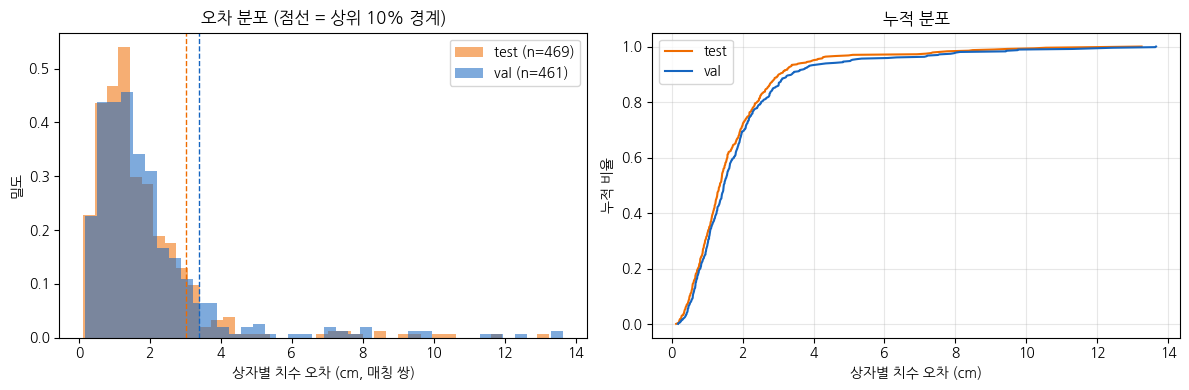

In [8]:
# [A-1] 오차 분포 — 소수의 큰 오차가 평균을 끌어올리나? · 실패 상자 정의 (상위 10%)
FAIL_Q = 0.90
for sp in ANA_SPLITS:
    A = BOX[sp]; thr = A['② cm'].quantile(FAIL_Q); A['실패'] = A['② cm'] >= thr
    share = A.loc[A['실패'], '② cm'].sum() / A['② cm'].sum() * 100
    print(f"{sp}: ② 중앙값 {A['② cm'].median():.2f} cm · 90% {thr:.2f} cm · 최대 {A['② cm'].max():.2f} cm → "
          f"상위 10% ({int(A['실패'].sum())}개)가 전체 오차 합의 {share:.0f}%")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for sp, c in zip(ANA_SPLITS, ('#ef6c00', '#1565c0')):
    A = BOX[sp]
    ax[0].hist(A['② cm'], bins=40, alpha=.55, color=c, label=f'{sp} (n={len(A)})', density=True)
    x = np.sort(A['② cm']); ax[1].plot(x, np.arange(1, len(x) + 1) / len(x), c=c, label=sp)
    ax[0].axvline(A['② cm'].quantile(FAIL_Q), c=c, ls='--', lw=1)
ax[0].set_xlabel('상자별 치수 오차 (cm, 매칭 쌍)'); ax[0].set_ylabel('밀도'); ax[0].legend(); ax[0].set_title('오차 분포 (점선 = 상위 10% 경계)')
ax[1].set_xlabel('상자별 치수 오차 (cm)'); ax[1].set_ylabel('누적 비율'); ax[1].grid(alpha=.3); ax[1].legend(); ax[1].set_title('누적 분포')
plt.tight_layout(); plt.savefig(f'{ANA_DIR}/error_dist.png', dpi=150); plt.show()


# **2. 요인별 · 다변수**

In [9]:
# [A-2] 요인별 구간표 — 구간마다 상자 수 · ② cm (영상 단위 bootstrap 95% CI) · ② % · 실패(상위 10%) 비율
#  - test가 주 결과, val 열은 같은 경향인지 확인용
FACTORS = [
    ('가려짐 평균', [-1e-9, 0.05, 0.2, 0.4, 1.01], ['< 0.05', '0.05 ~ 0.2', '0.2 ~ 0.4', '≥ 0.4']),
    ('쓴 프레임', [0, 2, 4, 7, 8], ['1 ~ 2장', '3 ~ 4장', '5 ~ 7장', '8장']),
    ('화면 끝 비율', [-1e-9, 1e-9, 0.5, 1.01], ['0', '0 ~ 0.5', '> 0.5']),
    ('짧은 변', [0, 10, 15, np.inf], ['≤ 10 cm', '10 ~ 15 cm', '> 15 cm']),
    ('긴 변', [0, 30, 40, 50, np.inf], ['~ 30 cm', '30 ~ 40 cm', '40 ~ 50 cm', '50 cm ~']),
    ('focal_mm', [0, 8, 15, 25, 1e3], ['≤ 8 mm (광각)', '8 ~ 15 mm', '15 ~ 25 mm', '> 25 mm']),
    ('n_gt', [0, 5, 10, np.inf], ['2 ~ 5개', '6 ~ 10개', '11개 ~']),
    ('화면 위치', [-1e-9, 1 / 3, 2 / 3, 1.01], ['가까움', '중간', '멂']),
    ('|sin|', [-1e-9, 0.1, 0.3, 1.01], ['< 0.1 (똑바로)', '0.1 ~ 0.3', '≥ 0.3 (기울어짐)']),
    ('축 순서 다름', None, None), ('주 원인', None, None)]


def factor_table(A, col, bins, labels):
    a = A.copy(); a['구간'] = pd.cut(a[col], bins, labels=labels) if bins is not None else a[col].astype(str)
    rows = []
    for b in (labels if bins is not None else sorted(a['구간'].unique())):
        x = a[a['구간'] == b]
        if not len(x): continue
        lo, hi = boot_ci(x, '② cm')
        rows.append({'구간': b, '상자': len(x), '② cm': x['② cm'].mean(), '95% CI': f'[{lo:.2f}, {hi:.2f}]', '② %': x['② %'].mean(),
                     '실패 비율 %': x['실패'].mean() * 100})
    return pd.DataFrame(rows).set_index('구간')


FT = {}
for col, bins, labels in FACTORS:
    t = factor_table(BOX['test'], col, bins, labels); v = factor_table(BOX['val'], col, bins, labels)
    FT[col] = t.join(v[['상자', '② cm', '실패 비율 %']].add_prefix('val '), how='left')
    hr(f'▶ [A-2] {col} — test (val은 같은 경향 확인용) · 전체 실패 비율 {BOX["test"]["실패"].mean() * 100:.0f}%')
    display(FT[col].round(2))



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-2] 가려짐 평균 — test (val은 같은 경향 확인용) · 전체 실패 비율 10%


,상자,② cm,95% CI,② %,실패 비율 %,val 상자,val ② cm,val 실패 비율 %
구간,,,,,,,,
< 0.05,27,1.67,"[1.17, 2.41]",8.12,14.81,40,2.01,7.50
0.05 ~ 0.2,88,1.70,"[1.43, 2.02]",7.48,11.36,93,2.09,12.90
0.2 ~ 0.4,147,1.67,"[1.42, 1.95]",8.55,9.52,144,2.01,11.11
≥ 0.4,207,1.84,"[1.62, 2.07]",9.87,9.18,184,1.82,8.70



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-2] 쓴 프레임 — test (val은 같은 경향 확인용) · 전체 실패 비율 10%


,상자,② cm,95% CI,② %,실패 비율 %,val 상자,val ② cm,val 실패 비율 %
구간,,,,,,,,
1 ~ 2장,4,5.28,"[2.51, 9.57]",28.00,50.00,8,3.90,50.00
3 ~ 4장,8,4.20,"[2.07, 7.10]",21.32,37.50,7,2.11,14.29
5 ~ 7장,18,2.83,"[1.84, 4.20]",18.00,22.22,10,4.68,30.00
8장,439,1.63,"[1.47, 1.80]",8.14,8.66,436,1.85,8.94



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-2] 화면 끝 비율 — test (val은 같은 경향 확인용) · 전체 실패 비율 10%


,상자,② cm,95% CI,② %,실패 비율 %,val 상자,val ② cm,val 실패 비율 %
구간,,,,,,,,
0,77,2.14,"[1.67, 2.71]",10.61,11.69,77,2.34,18.18
0 ~ 0.5,314,1.59,"[1.40, 1.81]",8.71,8.28,323,1.78,7.74
> 0.5,78,2.02,"[1.75, 2.32]",8.03,15.38,61,2.38,13.11


... (12 outputs left out)


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-2] 축 순서 다름 — test (val은 같은 경향 확인용) · 전체 실패 비율 10%


,상자,② cm,95% CI,② %,실패 비율 %,val 상자,val ② cm,val 실패 비율 %
구간,,,,,,,,
False,429,1.55,"[1.43, 1.67]",7.79,6.53,406,1.73,6.90
True,40,3.92,"[3.00, 4.86]",20.96,47.50,55,3.62,34.55



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-2] 주 원인 — test (val은 같은 경향 확인용) · 전체 실패 비율 10%


,상자,② cm,95% CI,② %,실패 비율 %,val 상자,val ② cm,val 실패 비율 %
구간,,,,,,,,
STEP 1 (w),54,2.09,"[1.40, 2.84]",10.40,14.81,52,3.20,26.92
STEP 2 (형태비),415,1.71,"[1.55, 1.86]",8.71,9.40,409,1.79,8.07


In [10]:
# [A-3] 다변수 — 요인을 함께 넣었을 때 무엇이 오차와 독립적으로 관련되나 (표준화 계수 · 영상 단위 cluster 표준오차)
#  - 종속 변수 = 상자별 ② % (상대 오차). 계수 = 요인이 1 표준편차 클 때 ② %가 몇 %p 달라지나
#  - Spearman 상관도 함께 (순위 기준, 이상치에 덜 민감)
try:
    import statsmodels.api as sm
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'statsmodels'], check=True); import statsmodels.api as sm
from scipy.stats import spearmanr
XCOLS = ['가려짐 평균', '쓴 프레임', '화면 끝 비율', '짧은 변', '긴 변', 'log_f', 'n_gt', '화면 위치', '|sin|']   # bbox px는 크기 · 위치로 정해져 겹치므로 뺌
REG = {}
for sp in ANA_SPLITS:
    A = BOX[sp].dropna(subset=XCOLS).copy(); X = A[XCOLS].astype(float)
    cols = [c for c in XCOLS if X[c].std(ddof=0) > 1e-9 * max(1.0, X[c].abs().max())]                    # 값이 모두 같은 요인은 뺌
    X = (X[cols] - X[cols].mean()) / X[cols].std(ddof=0)
    m = sm.OLS(A['② %'].values, sm.add_constant(X.values, has_constant='add')).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(A.vid)[0]})
    ci = np.asarray(m.conf_int())[1:]
    REG[sp] = pd.DataFrame({'계수 (%p / 1 SD)': m.params[1:], '95% CI': [f'[{a:+.2f}, {b:+.2f}]' for a, b in ci], 'p': m.pvalues[1:],
                            'Spearman ρ': [spearmanr(A[c], A['② %']).correlation for c in cols]}, index=cols).reindex(XCOLS)
    REG[sp]['유의 (p < 0.05)'] = np.where(REG[sp].p < 0.05, '○', '')
    hr(f'▶ [A-3] {sp} — 다변수 회귀 (② %, R² {m.rsquared:.2f}, 상자 {len(A)} · 영상 {A.vid.nunique()})')
    display(REG[sp].round(3))
both = [c for c in XCOLS if REG['test'].loc[c, 'p'] < 0.05 and REG['val'].loc[c, 'p'] < 0.05
        and np.sign(REG['test'].loc[c, '계수 (%p / 1 SD)']) == np.sign(REG['val'].loc[c, '계수 (%p / 1 SD)'])]
print('test · val 모두 유의하고 방향이 같은 요인:', both or '없음')



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-3] test — 다변수 회귀 (② %, R² 0.21, 상자 469 · 영상 50)


,계수 (%p / 1 SD),95% CI,p,Spearman ρ,유의 (p < 0.05)
가려짐 평균,0.165,"[-0.73, +1.06]",0.718,0.153,
쓴 프레임,-2.565,"[-3.61, -1.52]",0.000,-0.283,○
화면 끝 비율,-0.410,"[-0.98, +0.15]",0.155,-0.084,
짧은 변,-2.054,"[-2.84, -1.27]",0.000,-0.313,○
긴 변,0.498,"[-0.21, +1.20]",0.166,-0.153,
log_f,0.540,"[-0.19, +1.27]",0.146,0.052,
n_gt,0.582,"[-0.05, +1.21]",0.072,0.058,
화면 위치,0.465,"[-0.36, +1.29]",0.268,0.062,
|sin|,0.484,"[-0.16, +1.12]",0.138,0.053,



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-3] val — 다변수 회귀 (② %, R² 0.15, 상자 461 · 영상 49)


,계수 (%p / 1 SD),95% CI,p,Spearman ρ,유의 (p < 0.05)
가려짐 평균,-0.705,"[-1.58, +0.17]",0.116,0.006,
쓴 프레임,-1.835,"[-3.11, -0.56]",0.005,-0.277,○
화면 끝 비율,0.652,"[-0.63, +1.93]",0.317,-0.091,
짧은 변,-2.048,"[-2.67, -1.43]",0.000,-0.313,○
긴 변,-1.192,"[-2.60, +0.22]",0.098,-0.199,
log_f,1.303,"[+0.28, +2.33]",0.013,0.041,○
n_gt,2.072,"[+0.97, +3.17]",0.000,0.111,○
화면 위치,0.651,"[-0.17, +1.47]",0.122,0.120,
|sin|,-0.994,"[-1.97, -0.02]",0.046,-0.055,○


test · val 모두 유의하고 방향이 같은 요인: ['쓴 프레임', '짧은 변']


# **3. 원인 분해 · 정성 분석**

In [11]:
# [A-4] 원인 분해 — 실패 상자는 무엇이 틀렸나 (w · 형태비 · 변 순위 · 축 순서)
for sp in ANA_SPLITS:
    A = BOX[sp]; rows = {}
    for name, x in (('실패 (상위 10%)', A[A['실패']]), ('나머지', A[~A['실패']])):
        rows[name] = {'상자': len(x), '② cm': x['② cm'].mean(), '|w 오차| %': x['w 오차 %'].abs().mean(),
                      '|log d/w 오차|': x.e_dw.abs().mean(), '|log h/w 오차|': x.e_hw.abs().mean(),
                      'STEP 1만 cm': x['STEP 1만 cm'].mean(), 'STEP 2만 cm': x['STEP 2만 cm'].mean(),
                      '주 원인 STEP 2 %': (x['주 원인'] == 'STEP 2 (형태비)').mean() * 100, '축 순서 다름 %': x['축 순서 다름'].mean() * 100,
                      '긴 변 오차': x['긴 변 오차'].mean(), '중간 변 오차': x['중간 변 오차'].mean(), '짧은 변 오차': x['짧은 변 오차'].mean()}
    hr(f'▶ [A-4] {sp} — 실패 상자 vs 나머지 (원인 분해)')
    display(pd.DataFrame(rows).T.round(3))
    print(f"  상관: w 오차 vs d/w 오차 {np.corrcoef(A.e_w, A.e_dw)[0, 1]:+.2f} · w vs h/w {np.corrcoef(A.e_w, A.e_hw)[0, 1]:+.2f} (음수 = 결합할 때 상쇄)")



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-4] test — 실패 상자 vs 나머지 (원인 분해)


,상자,② cm,|w 오차| %,|log d/w 오차|,|log h/w 오차|,STEP 1만 cm,STEP 2만 cm,주 원인 STEP 2 %,축 순서 다름 %,긴 변 오차,중간 변 오차,짧은 변 오차
실패 (상위 10%),47.0,5.265,24.526,0.452,0.374,4.512,5.872,82.979,40.426,8.332,4.098,3.364
나머지,422.0,1.359,2.003,0.098,0.110,0.437,1.253,89.100,4.976,1.511,1.258,1.308


  상관: w 오차 vs d/w 오차 -0.71 · w vs h/w -0.61 (음수 = 결합할 때 상쇄)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-4] val — 실패 상자 vs 나머지 (원인 분해)


,상자,② cm,|w 오차| %,|log d/w 오차|,|log h/w 오차|,STEP 1만 cm,STEP 2만 cm,주 원인 STEP 2 %,축 순서 다름 %,긴 변 오차,중간 변 오차,짧은 변 오차
실패 (상위 10%),47.0,6.243,30.567,0.500,0.390,5.505,6.249,70.213,40.426,10.120,5.130,3.477
나머지,414.0,1.465,2.295,0.102,0.125,0.488,1.362,90.821,8.696,1.568,1.335,1.493


  상관: w 오차 vs d/w 오차 -0.66 · w vs h/w -0.58 (음수 = 결합할 때 상쇄)


In [15]:
# [A-4b] 큰 실패는 왜 생기나 — ① w · 형태비가 어떻게 틀렸나 ② 짧은 트랙(쓴 프레임 ≤ 4장)은 왜 생기나
#  - '축 순서 다름'은 원인이 아니라 표시: 채점은 세 변을 정렬하므로 축만 바뀐 예측은 벌점이 없다.
#    값이 크게 틀려 크기 순위가 뒤집힐 때 함께 나타남 → 여기서는 "무엇이 어떻게 틀렸나"를 직접 본다
#  - 가설: (가) 비스듬히 놓인 상자는 bbox 가로가 옆면까지 잡아 w 과대 · d/w 과소
#          (나) 정사각형에 가까운 상자(w ≈ d)는 작은 오차로도 순위가 뒤집힘 (오차는 작은데 표시만 됨)
SQUARE = 0.15                                                           # |log(정답 w / 정답 d)| < 0.15 ≈ 두 변 차이 15% 이내
for sp in ANA_SPLITS:
    A = BOX[sp]; A['w 과대'] = A.w > A.w_gt; A['정사각형에 가까움'] = np.abs(np.log(A.w_gt / A.d_gt)) < SQUARE
    A['d/w 과소'] = A.e_dw < 0
    rows = {}
    for name, x in (('실패 (상위 10%)', A[A['실패']]), ('나머지', A[~A['실패']]),
                    ('축 순서 다름 · 실패', A[A['축 순서 다름'] & A['실패']]), ('축 순서 다름 · 실패 아님', A[A['축 순서 다름'] & ~A['실패']])):
        rows[name] = {'상자': len(x), '② cm': x['② cm'].mean(), 'w 오차 % (부호 있음)': x['w 오차 %'].mean(),
                      'w 과대 %': x['w 과대'].mean() * 100, 'w 과대 · d/w 과소 함께 %': (x['w 과대'] & x['d/w 과소']).mean() * 100,
                      '정사각형에 가까움 %': x['정사각형에 가까움'].mean() * 100, '|sin| 평균': x['|sin|'].mean(),
                      '화면 위치 평균': x['화면 위치'].mean(), '쓴 프레임 평균': x['쓴 프레임'].mean(), '장면 상자 수 평균': x.n_gt.mean(),
                      '가려짐 평균': x['가려짐 평균'].mean()}
    hr(f'▶ [A-4b] {sp} — 큰 실패에서 w · 형태비가 어떻게 틀렸나 (가설 (가) w 과대 · d/w 과소, (나) 정사각형)')
    display(pd.DataFrame(rows).T.round(2))

# ② 짧은 트랙: 영상 시작 · 끝에 걸렸나, 중간에 끊겼나 (트랙 길이 = 그 트랙이 관측된 샘플 프레임 수)
def track_span(sp, vid, tid):
    tr = RECS[sp][vid]['tracks']; vmax = max(int(np.max(t['fi'])) for t in tr)
    t = next(t for t in tr if int(t['tid']) == int(tid)); f0, f1 = int(np.min(t['fi'])), int(np.max(t['fi']))
    where = '영상 시작에 걸림' if f0 <= 2 else ('영상 끝에 걸림' if f1 >= vmax - 2 else '중간 (가림 · 끊김)')
    return pd.Series({'관측 수': len(t['fi']), '보인 시간 s': (f1 - f0) * 0.1, '위치': where})


for sp in ANA_SPLITS:
    S = BOX[sp][BOX[sp]['쓴 프레임'] <= 4].copy()
    if not len(S): continue
    S = S.join(S.apply(lambda r: track_span(sp, r.vid, r.tid), axis=1))
    hr(f'▶ [A-4b] {sp} — 짧은 트랙 (쓴 프레임 ≤ 4장, {len(S)}개): 어디서 생기나')
    display(S.groupby('위치').agg(상자=('② cm', 'size'), 오차_cm=('② cm', 'mean'), 관측_수=('관측 수', 'mean'),
                                  보인_시간_s=('보인 시간 s', 'mean'), 실패_비율=('실패', 'mean')).round(2))
    display(S.sort_values('② cm', ascending=False)[['vid', 'tid', '② cm', '쓴 프레임', '관측 수', '보인 시간 s', '위치', '가려짐 평균', '화면 끝 비율']].head(10).round(2))



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-4b] test — 큰 실패에서 w · 형태비가 어떻게 틀렸나 (가설 (가) w 과대 · d/w 과소, (나) 정사각형)


,상자,② cm,w 오차 % (부호 있음),w 과대 %,w 과대 · d/w 과소 함께 %,정사각형에 가까움 %,|sin| 평균,화면 위치 평균,쓴 프레임 평균,장면 상자 수 평균,가려짐 평균
실패 (상위 10%),47.0,5.26,-0.88,51.06,38.30,23.40,0.20,0.06,7.28,11.23,0.42
나머지,422.0,1.36,0.21,47.16,27.01,21.80,0.18,0.03,7.86,11.17,0.40
축 순서 다름 · 실패,19.0,6.33,1.45,36.84,31.58,42.11,0.17,0.11,6.68,12.37,0.52
축 순서 다름 · 실패 아님,21.0,1.74,0.86,57.14,47.62,66.67,0.21,0.03,7.62,12.81,0.64



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-4b] val — 큰 실패에서 w · 형태비가 어떻게 틀렸나 (가설 (가) w 과대 · d/w 과소, (나) 정사각형)


,상자,② cm,w 오차 % (부호 있음),w 과대 %,w 과대 · d/w 과소 함께 %,정사각형에 가까움 %,|sin| 평균,화면 위치 평균,쓴 프레임 평균,장면 상자 수 평균,가려짐 평균
실패 (상위 10%),47.0,6.24,-4.74,40.43,27.66,14.89,0.13,0.07,7.23,12.45,0.34
나머지,414.0,1.47,0.51,54.59,27.05,27.54,0.17,0.03,7.85,10.87,0.37
축 순서 다름 · 실패,19.0,7.31,-17.36,26.32,21.05,21.05,0.13,0.08,6.74,13.11,0.44
축 순서 다름 · 실패 아님,36.0,1.68,1.42,66.67,30.56,75.00,0.18,0.05,7.50,10.22,0.42



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-4b] test — 짧은 트랙 (쓴 프레임 ≤ 4장, 12개): 어디서 생기나


,상자,오차_cm,관측_수,보인_시간_s,실패_비율
위치,,,,,
영상 끝에 걸림,3,2.98,51.67,5.37,0.67
영상 시작에 걸림,2,8.11,7.50,0.70,0.50
중간 (가림 · 끊김),7,4.23,12.71,1.79,0.29


,vid,tid,② cm,쓴 프레임,관측 수,보인 시간 s,위치,가려짐 평균,화면 끝 비율
59,test_004,4,13.25,3,8,0.7,영상 시작에 걸림,0.84,0.00
209,test_019,17,11.86,1,2,0.1,중간 (가림 · 끊김),0.20,0.00
212,test_020,0,7.17,3,46,4.9,중간 (가림 · 끊김),0.29,0.67
107,test_009,9,4.24,2,71,4.0,영상 끝에 걸림,0.94,1.00
364,test_036,0,3.18,4,73,8.1,영상 끝에 걸림,0.65,0.50
91,test_007,7,2.96,4,7,0.7,영상 시작에 걸림,1.00,0.00
303,test_028,2,2.96,3,10,3.9,중간 (가림 · 끊김),0.28,0.67
331,test_031,7,2.72,1,2,0.2,중간 (가림 · 끊김),1.00,0.00
23,test_001,3,2.29,2,4,0.4,중간 (가림 · 끊김),1.00,0.00
211,test_019,8,1.83,4,17,2.3,중간 (가림 · 끊김),0.94,0.00



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-4b] val — 짧은 트랙 (쓴 프레임 ≤ 4장, 15개): 어디서 생기나


,상자,오차_cm,관측_수,보인_시간_s,실패_비율
위치,,,,,
영상 끝에 걸림,1,2.10,37.00,4.00,0.00
영상 시작에 걸림,2,3.23,2.50,0.20,0.50
중간 (가림 · 끊김),12,3.12,7.17,1.15,0.33


,vid,tid,② cm,쓴 프레임,관측 수,보인 시간 s,위치,가려짐 평균,화면 끝 비율
286,val_027,5,9.44,1,2,0.1,중간 (가림 · 끊김),0.36,0.00
184,val_018,3,4.84,1,2,0.1,중간 (가림 · 끊김),0.83,0.00
151,val_014,3,4.62,2,3,0.2,영상 시작에 걸림,1.00,0.00
16,val_000,18,4.22,2,3,0.2,중간 (가림 · 끊김),0.73,0.00
164,val_016,3,3.58,3,6,1.8,중간 (가림 · 끊김),0.26,0.00
115,val_010,2,2.78,4,16,1.6,중간 (가림 · 끊김),1.00,0.25
174,val_017,7,2.61,1,3,0.2,중간 (가림 · 끊김),0.00,0.00
235,val_023,9,2.36,1,3,3.3,중간 (가림 · 끊김),0.63,0.00
132,val_012,10,2.24,4,9,1.4,중간 (가림 · 끊김),0.99,0.00
416,val_041,6,2.10,4,37,4.0,영상 끝에 걸림,0.49,0.75


In [14]:
# [A-5] 정성 분석 — test 오차 상위 TOP_K개: 요인 표 + 상자마다 [전체 화면 · 대표 crop · 가상 3D 상자]
#  - 대표 프레임 = 치수 추정에 쓴 프레임 중 가려짐이 가장 적은 것. 전체 화면의 노란 상자 = 그 상자, 회색 = 같은 프레임의 다른 트랙
#  - 3D: 예측 주황 · 정답 초록 점선 (같은 축척)
TOP_K = 20  #@param {type:"integer"}
fmt = lambda a: 'x'.join(f'{v:.0f}' for v in a)
A = BOX['test']; TOP = A.sort_values('② cm', ascending=False).head(TOP_K).reset_index(drop=True)
cols = ['vid', 'tid', '② cm', '② %', '주 원인', '축 순서 다름', '가려짐 평균', '쓴 프레임', '화면 끝 비율', '짧은 변', 'focal_mm', 'n_gt', '화면 위치']
show = TOP[cols].copy(); show.insert(2, '예측 w×d×h', [fmt(r) for r in TOP[['w', 'd', 'h']].values])
show.insert(3, '정답 w×d×h', [fmt(r) for r in TOP[['w_gt', 'd_gt', 'h_gt']].values])
hr(f'▶ [A-5] test 오차 상위 {TOP_K}개'); display(show.round(2))
show.to_csv(f'{ANA_DIR}/test_top{TOP_K}.csv', index=False)


def cuboid(ax, w, d, h, color, ls, label):
    V = np.array([[x, y, z] for x in (0, w) for y in (0, d) for z in (0, h)])
    for a_ in range(8):
        for b_ in range(a_ + 1, 8):
            if np.sum(V[a_] != V[b_]) == 1:
                ax.plot(*zip(V[a_], V[b_]), color=color, ls=ls, lw=2, label=label if (a_, b_) == (0, 1) else None)


def others_at(sp, vid, fi, tid):
    out = []
    for t in RECS[sp][vid]['tracks']:
        if int(t['tid']) == int(tid): continue
        k = np.where(np.asarray(t['fi']) == fi)[0]
        if len(k): out.append(t['bbox'][k[0]])
    return out


PER_FIG = 6
for s0 in range(0, len(TOP), PER_FIG):
    part = TOP.iloc[s0:s0 + PER_FIG]; fig = plt.figure(figsize=(15, 3.6 * len(part)))
    for j, (_, r) in enumerate(part.iterrows()):
        cap = cv2.VideoCapture(video_path('test', r.vid)); cap.set(cv2.CAP_PROP_POS_FRAMES, int(r['대표_rep_fi']) * int(r['대표_step']))
        ok_, fr = cap.read(); cap.release()
        b = [r['대표_x1'], r['대표_y1'], r['대표_x2'], r['대표_y2']]
        ax1 = fig.add_subplot(len(part), 3, 3 * j + 1); ax2 = fig.add_subplot(len(part), 3, 3 * j + 2)
        if ok_:
            full = fr.copy()
            for o in others_at('test', r.vid, int(r['대표_rep_fi']), r.tid): cv2.rectangle(full, tuple(map(int, o[:2])), tuple(map(int, o[2:])), (170, 170, 170), 2)
            cv2.rectangle(full, tuple(map(int, b[:2])), tuple(map(int, b[2:])), (0, 230, 255), 4)
            ax1.imshow(cv2.cvtColor(full, cv2.COLOR_BGR2RGB))
            H_, W_ = fr.shape[:2]; px, py = (b[2] - b[0]) * 0.4, (b[3] - b[1]) * 0.4
            c = fr[int(max(0, b[1] - py)):int(min(H_, b[3] + py)), int(max(0, b[0] - px)):int(min(W_, b[2] + px))]
            ax2.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
        ax1.axis('off'); ax2.axis('off')
        ax1.set_title(f'#{s0 + j + 1} {r.vid} T{r.tid} · focal {r.focal_mm:.0f} mm · 장면 상자 {r.n_gt}', fontsize=10)
        ax2.set_title(f'가려짐 {r["대표_occ"]:.2f} (평균 {r["가려짐 평균"]:.2f}) · {int(r["쓴 프레임"])}장 · 화면 끝 {r["화면 끝 비율"]:.0%}', fontsize=10)
        ax3 = fig.add_subplot(len(part), 3, 3 * j + 3, projection='3d')
        P3, G3 = r[['w', 'd', 'h']].values.astype(float), r[['w_gt', 'd_gt', 'h_gt']].values.astype(float)
        cuboid(ax3, *P3, '#ef6c00', '-', f'예측 {fmt(P3)}'); cuboid(ax3, *G3, '#2e7d32', '--', f'정답 {fmt(G3)}')
        L = max(P3.max(), G3.max()) * 1.05
        ax3.set_xlim(0, L); ax3.set_ylim(0, L); ax3.set_zlim(0, L); ax3.set_box_aspect((1, 1, 1)); ax3.view_init(elev=22, azim=-55)
        ax3.set_xlabel('w'); ax3.set_ylabel('d'); ax3.set_zlabel('h'); ax3.tick_params(labelsize=7); ax3.legend(fontsize=7, loc='upper left')
        ax3.set_title(f'오차 {r["② cm"]:.1f} cm ({r["② %"]:.0f}%) · 주 원인 {r["주 원인"]}' + (' · 축 순서 다름' if r['축 순서 다름'] else ''), fontsize=10)
    plt.tight_layout(); p_ = f'{ANA_DIR}/test_top_{s0 + 1}-{s0 + len(part)}.png'; plt.savefig(p_, dpi=110); plt.show(); print(f'💾 {p_}')


Output hidden; open in https://colab.research.google.com to view.

# **4. 시스템 오류 (③)**

In [13]:
# [A-6] 시스템 오류 (지표 ③) — 미검출 · 정답 없는 트랙이 ③을 얼마나 키우나, 미검출 상자는 어떤 상자인가
for sp in ANA_SPLITS:
    P = pd.read_csv(f'{OUT2_DIR}/{sp}_proposed_preds.csv')
    R = box_records(LABELS[sp], MAPS[sp], P.assign(vid=P.vid.astype(str)))
    tot = R.cm.sum(); rows = {}
    for k in ('매칭', '미검출', '정답 없음'):
        x = R[R.kind == k]; rows[k] = {'상자 · 트랙': len(x), '평균 cm': x.cm.mean(), '③ 합에서 차지 %': x.cm.sum() / tot * 100}
    hr(f"▶ [A-6] {sp} — ③ 구성 (③ = {R.cm.mean():.3f} cm, ② = {R[R.kind == '매칭'].cm.mean():.3f} cm)")
    display(pd.DataFrame(rows).T.round(2))
    miss = R[R.kind == '미검출']; mt = R[R.kind == '매칭']
    print(f"  미검출 상자: 가장 긴 변 평균 {miss['long'].mean():.1f} cm (매칭 {mt['long'].mean():.1f}) · 가장 짧은 변 {miss['short'].mean():.1f} cm "
          f"(매칭 {mt['short'].mean():.1f}) · 장면 상자 수 평균 {miss.n_box.mean():.1f} (매칭 {mt.n_box.mean():.1f})")
    print(f"  미검출이 나온 영상: {miss.vid.nunique()}개 · {miss.groupby('vid').size().sort_values(ascending=False).head(5).to_dict()}")



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-6] test — ③ 구성 (③ = 2.155 cm, ② = 1.751 cm)


,상자 · 트랙,평균 cm,③ 합에서 차지 %
매칭,469.0,1.75,78.70
미검출,7.0,15.52,10.42
정답 없음,8.0,14.19,10.88


  미검출 상자: 가장 긴 변 평균 21.2 cm (매칭 32.3) · 가장 짧은 변 9.6 cm (매칭 14.1) · 장면 상자 수 평균 11.3 (매칭 11.2)
  미검출이 나온 영상: 6개 · {'test_002': 2, 'test_009': 1, 'test_017': 1, 'test_018': 1, 'test_037': 1}

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
▶ [A-6] val — ③ 구성 (③ = 2.439 cm, ② = 1.952 cm)


,상자 · 트랙,평균 cm,③ 합에서 차지 %
매칭,461.0,1.95,78.00
미검출,6.0,21.40,11.13
정답 없음,6.0,20.91,10.87


  미검출 상자: 가장 긴 변 평균 29.7 cm (매칭 31.5) · 가장 짧은 변 15.1 cm (매칭 14.2) · 장면 상자 수 평균 13.0 (매칭 11.0)
  미검출이 나온 영상: 5개 · {'val_028': 2, 'val_001': 1, 'val_010': 1, 'val_030': 1, 'val_037': 1}


# **5. 결과 정리**

상자별 치수 오차는 중앙값 1.36 cm로 대부분 작고, 상위 10%(≥ 3.0 cm)가 전체 오차 합의 30%를 차지한다(val 33%). 다변수 분석에서 test · val 모두 유의한 요인은 치수 추정에 쓴 프레임 수(1~2장 5.3 cm → 8장 1.6 cm)와 짧은 변(납작할수록 상대 오차 증가)이었다. 가려짐은 오차와 관련이 거의 없었는데, 가려짐이 적은 프레임을 골라 쓰기 때문으로 해석된다. 프레임이 4장 이하인 상자는 대부분(test 7/12 · val 12/15) 다른 상자에 가려 잠깐만 보인 경우였다.

오차 상위 사례를 직접 확인하면, 실패의 대부분은 치수 모델이 아니라 bbox가 상자의 실제 범위와 다른 경우였다. ① 앞 상자에 가리거나 화면 끝에 잘려 bbox가 상자의 일부만 잡으면, 치수 전체가 몇 배 작게 나왔다(14개 중 7개, 최대 13 cm). ② 이웃 상자가 함께 잡히거나 겹쳐 보이면, w · d · h가 과대 추정되었다(4개). ③ 광각(5 mm) 영상의 화면 끝 상자에서도 큰 오차가 있었다(3개). 크기 순위가 뒤집힌 예측(실패 상자의 40%)도 대부분 이 bbox 오류에서 생겼고, 순위만 뒤집히고 오차가 작은 경우는 정사각형에 가까운 상자였다(67 ~ 75%). 미검출 · 정답 없는 트랙은 3%이지만 ③ 오차 합의 21%를 차지한다.

개선 방향: 트랙 안에서 bbox가 다른 프레임보다 크게 작거나 큰 프레임(일부만 보임 · 합쳐짐)을 프레임 선택에서 빼는 방법, 가려진 부분까지 추정하는 amodal 분할.